# 🌱 AI-Based Crop Recommendation System Using Soil Analysis Parameters
### Machine Learning & Precision Agriculture Mini-Project
**Target Examination**: External Practical Examination & Project Defense  
**Tech Stack**: Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, Joblib  

---

### Project Problem Statement & Objective:
Traditional agricultural practices often suffer from improper crop selection due to lack of scientific soil analysis and localized environmental data. Planting unsuitable crops leads to reduced yield, soil nutrient depletion, and severe financial distress for farmers.

This project builds an intelligent **Crop Recommendation Decision Support System**. Given:
1. **Soil Chemical Parameters**: Nitrogen ($N$), Phosphorus ($P$), Potassium ($K$), and Soil Acidity/Alkalinity ($pH$).
2. **Climatic Parameters**: Ambient Temperature (°C), Relative Humidity (%), and Rainfall (mm).

The system analyzes these features using supervised machine learning algorithms to recommend the most suitable crop with high confidence.


## 1. Import Required Libraries
We import standard data science and machine learning libraries:
- `pandas` & `numpy` for data manipulation and numerical operations.
- `matplotlib` & `seaborn` for exploratory data visualizations.
- `scikit-learn` for data preprocessing, pipeline construction, classifier algorithms, and evaluation metrics.
- `joblib` for model serialization.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Plot styling configuration
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid')

print("All libraries successfully imported!")


All libraries successfully imported!


## 2. Data Exploration
We load the dataset `Crop_recommendation.csv` and inspect:
- Dimensions (shape) of the dataset
- Feature column names and data types
- First 5 rows of observations
- Statistical summary (mean, standard deviation, min, max, quartiles)
- Missing values and duplicate records
- Unique crop classes and class balance


In [2]:
# Load the dataset
dataset_path = 'Crop_recommendation.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Dataset Information ---")
df.info()


Dataset Shape: 2200 rows, 8 columns

--- First 5 Records ---


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [3]:
# Summary statistics of numerical features
print("--- Statistical Summary ---")
display(df.describe().T)

# Check for missing values and duplicates
missing_count = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print(f"Total Missing Values across all columns:\n{missing_count}")
print(f"\nTotal Duplicate Records: {duplicate_count}")

# Check unique crop classes
unique_crops = df['label'].unique()
print(f"\nTotal Unique Crops: {len(unique_crops)}")
print(f"Crop List:\n{list(unique_crops)}")


--- Statistical Summary ---


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


Total Missing Values across all columns:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total Duplicate Records: 0

Total Unique Crops: 22
Crop List:
['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas', 'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate', 'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple', 'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee']


## 3. Exploratory Data Analysis (EDA)
EDA provides critical insights into how soil nutrients and environmental conditions correlate with crop categories.
We examine:
1. **Target Class Balance**: Confirming whether the dataset is balanced across all 22 crop classes.
2. **Correlation Matrix**: Identifying relationships among $N$, $P$, $K$, temperature, humidity, pH, and rainfall.
3. **Distribution of Primary Soil Nutrients ($N, P, K$)**: Boxplots and histogram distributions.
4. **Distribution of Environmental Factors**: Temperature, Humidity, pH, and Rainfall.
5. **Crop-wise Nutrient Profiles**: Average nutrient demands for representative crops.


/tmp/ipykernel_24092/2150828091.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='label', order=order, palette='viridis')


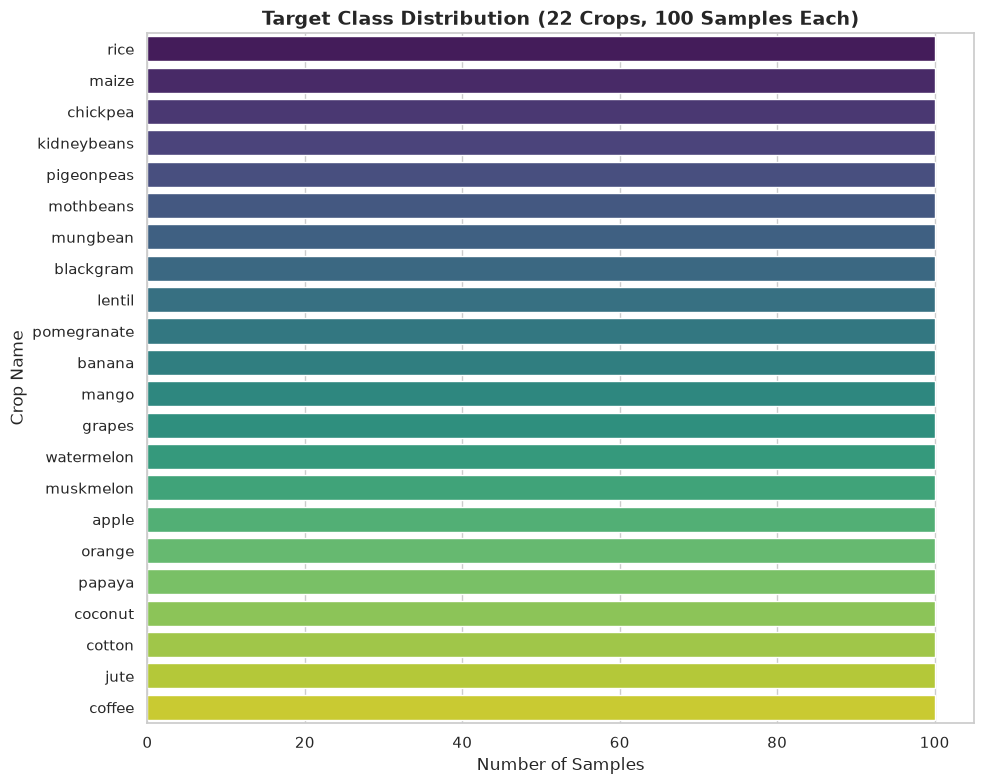

Key Insight: The dataset is perfectly balanced with exactly 100 samples per crop class (total 2200 samples).


In [4]:
# 1. Target Class Distribution
plt.figure(figsize=(10, 8))
order = df['label'].value_counts().index
sns.countplot(data=df, y='label', order=order, palette='viridis')
plt.title('Target Class Distribution (22 Crops, 100 Samples Each)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Samples')
plt.ylabel('Crop Name')
plt.tight_layout()
plt.show()

print("Key Insight: The dataset is perfectly balanced with exactly 100 samples per crop class (total 2200 samples).")


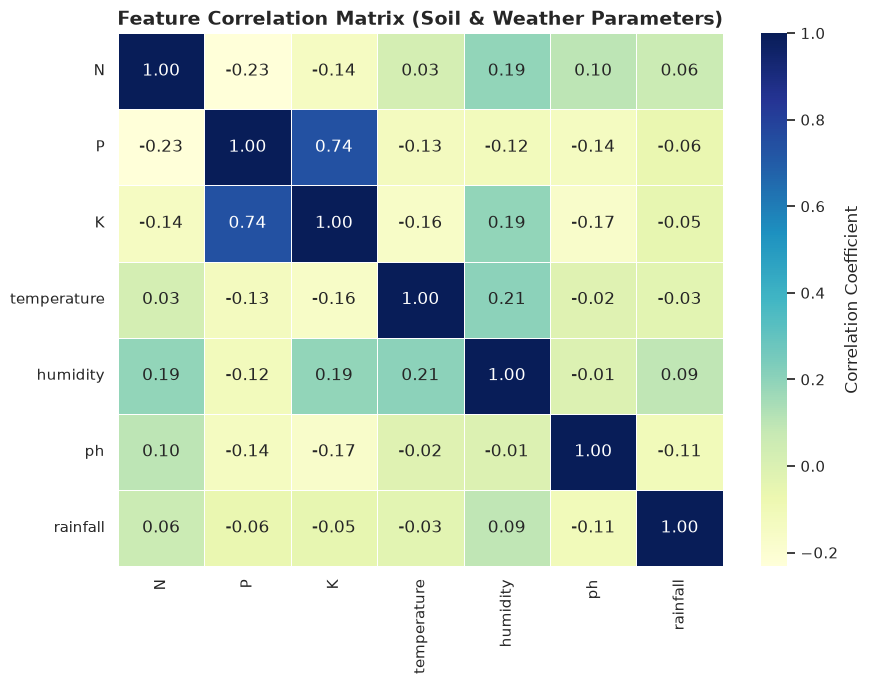

Key Insight: Phosphorus (P) and Potassium (K) show a strong positive correlation (r = 0.74), reflecting shared geological and fertilizer characteristics.


In [5]:
# 2. Correlation Matrix Heatmap
plt.figure(figsize=(9, 7))
numeric_df = df.drop(columns=['label'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='YlGnBu', linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Feature Correlation Matrix (Soil & Weather Parameters)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Key Insight: Phosphorus (P) and Potassium (K) show a strong positive correlation (r = 0.74), reflecting shared geological and fertilizer characteristics.")


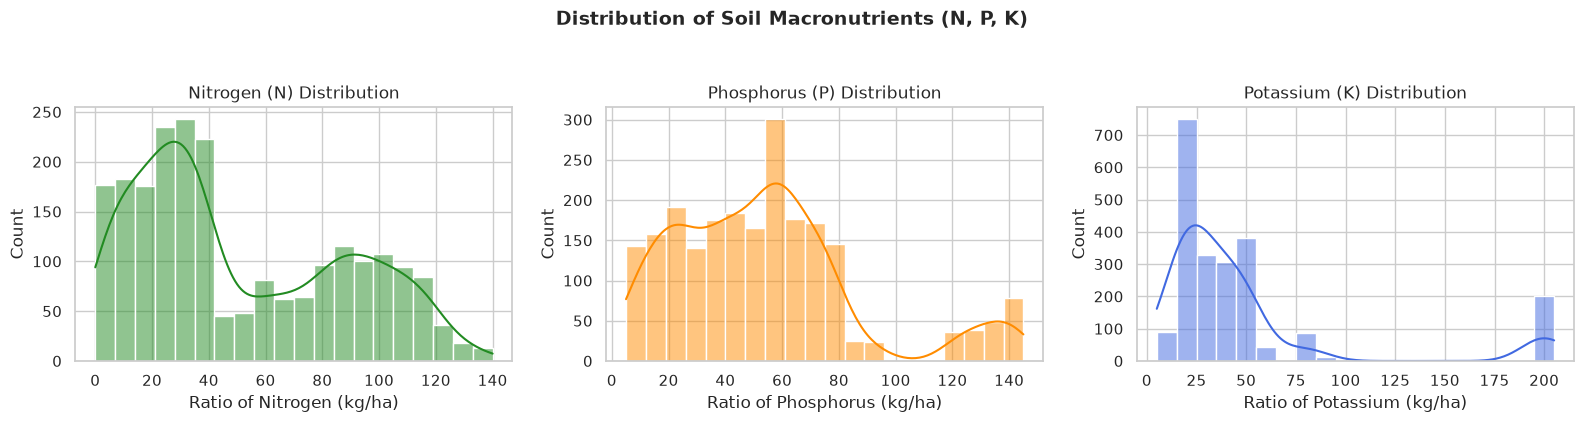

In [6]:
# 3. Distribution of Primary Soil Nutrients (NPK)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['N'], kde=True, ax=axes[0], color='forestgreen', bins=20)
axes[0].set_title('Nitrogen (N) Distribution')
axes[0].set_xlabel('Ratio of Nitrogen (kg/ha)')

sns.histplot(df['P'], kde=True, ax=axes[1], color='darkorange', bins=20)
axes[1].set_title('Phosphorus (P) Distribution')
axes[1].set_xlabel('Ratio of Phosphorus (kg/ha)')

sns.histplot(df['K'], kde=True, ax=axes[2], color='royalblue', bins=20)
axes[2].set_title('Potassium (K) Distribution')
axes[2].set_xlabel('Ratio of Potassium (kg/ha)')

plt.suptitle('Distribution of Soil Macronutrients (N, P, K)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()


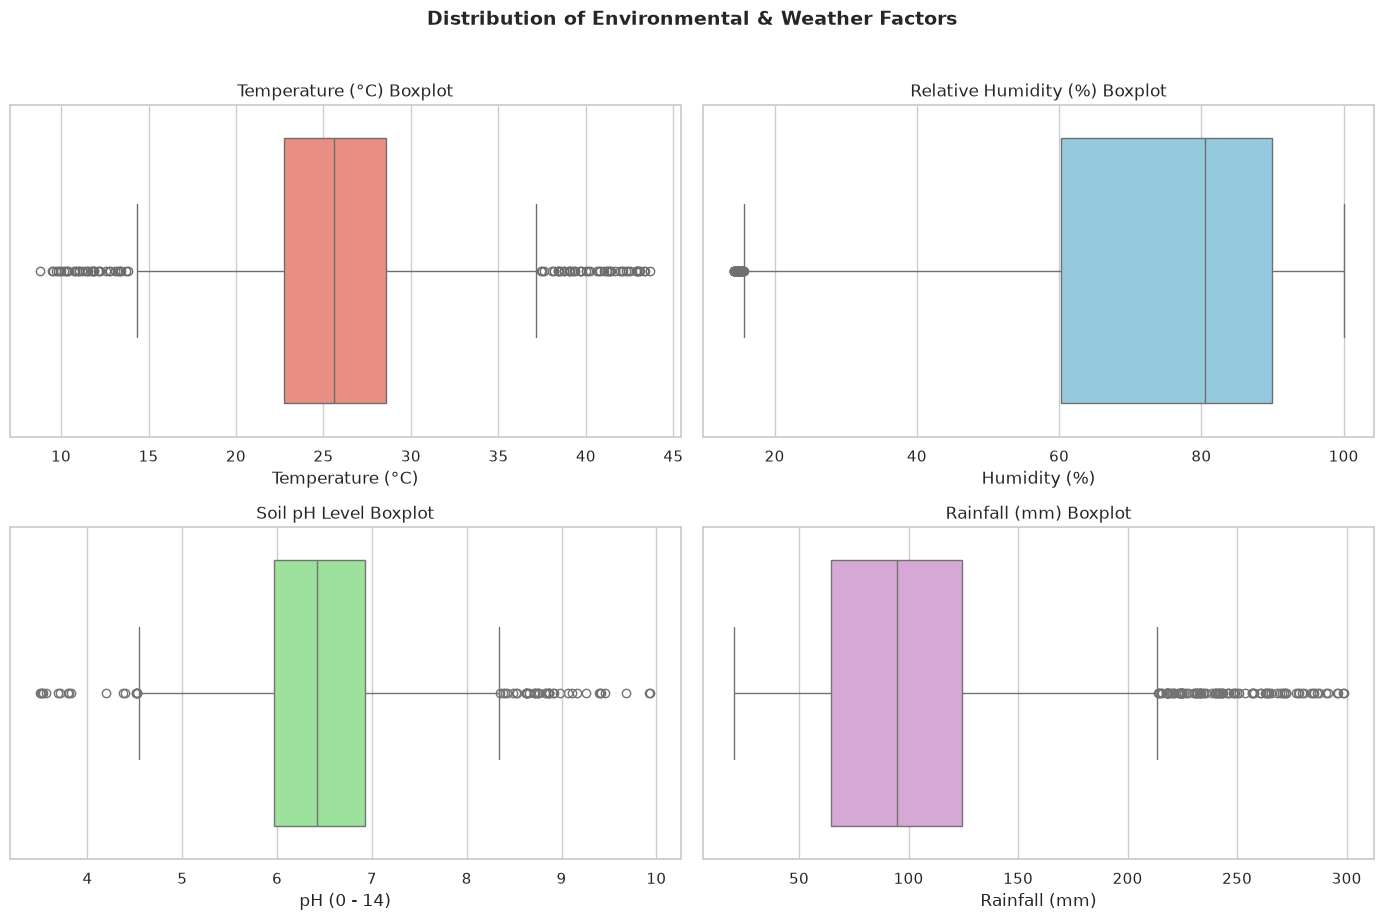

In [7]:
# 4. Distribution of Climatic & Environmental Parameters
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(x=df['temperature'], ax=axes[0, 0], color='salmon')
axes[0, 0].set_title('Temperature (°C) Boxplot')
axes[0, 0].set_xlabel('Temperature (°C)')

sns.boxplot(x=df['humidity'], ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Relative Humidity (%) Boxplot')
axes[0, 1].set_xlabel('Humidity (%)')

sns.boxplot(x=df['ph'], ax=axes[1, 0], color='lightgreen')
axes[1, 0].set_title('Soil pH Level Boxplot')
axes[1, 0].set_xlabel('pH (0 - 14)')

sns.boxplot(x=df['rainfall'], ax=axes[1, 1], color='plum')
axes[1, 1].set_title('Rainfall (mm) Boxplot')
axes[1, 1].set_xlabel('Rainfall (mm)')

plt.suptitle('Distribution of Environmental & Weather Factors', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


/tmp/ipykernel_24092/243905054.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_n.values, y=top_n.index, ax=axes[0], palette='Greens_r')
/tmp/ipykernel_24092/243905054.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rain.values, y=top_rain.index, ax=axes[1], palette='Blues_r')


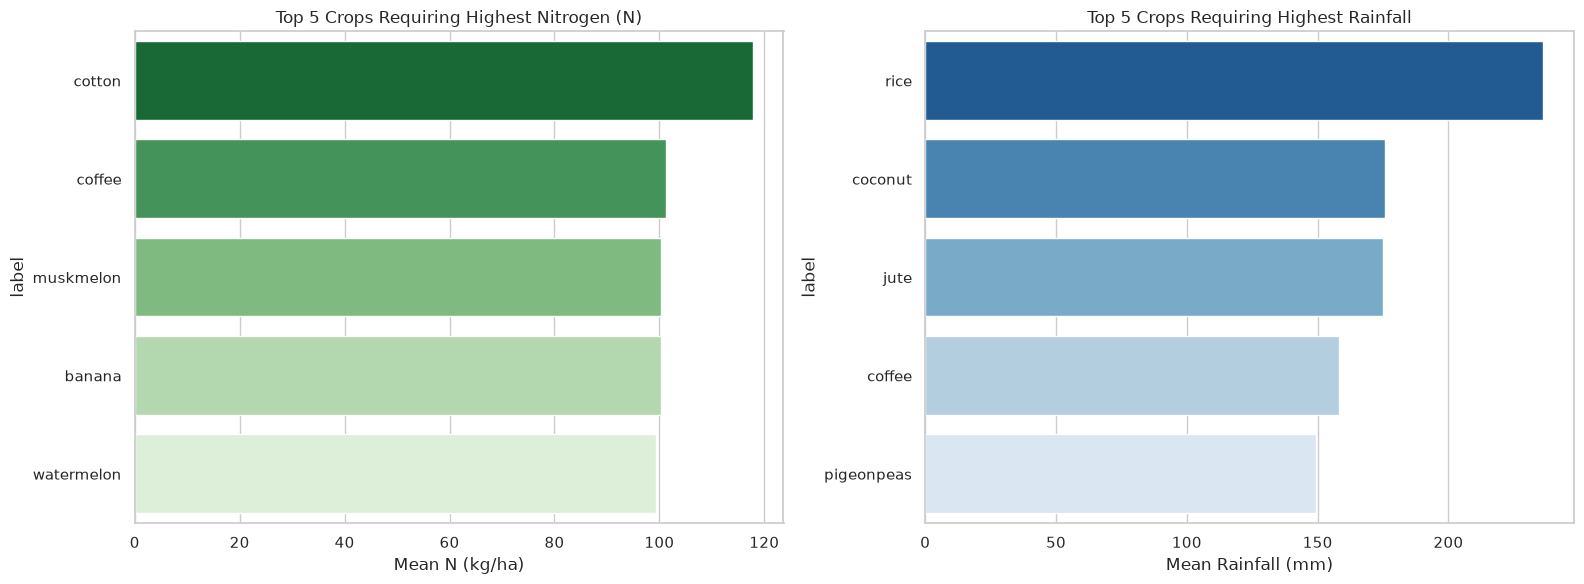

In [8]:
# 5. Crop-Wise Nutrient Requirements (Mean Comparison)
crop_means = df.groupby('label').mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 5 crops requiring highest Nitrogen
top_n = crop_means['N'].nlargest(5)
sns.barplot(x=top_n.values, y=top_n.index, ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 5 Crops Requiring Highest Nitrogen (N)')
axes[0].set_xlabel('Mean N (kg/ha)')

# Top 5 crops requiring highest Rainfall
top_rain = crop_means['rainfall'].nlargest(5)
sns.barplot(x=top_rain.values, y=top_rain.index, ax=axes[1], palette='Blues_r')
axes[1].set_title('Top 5 Crops Requiring Highest Rainfall')
axes[1].set_xlabel('Mean Rainfall (mm)')

plt.tight_layout()
plt.show()


## 4. Data Preprocessing & Train-Test Split
Proper data preprocessing is essential to prevent data leakage and ensure model generalization:

1. **Feature Separation ($X$) and Target ($y$)**:
   - $X = [N, P, K, \text{temperature}, \text{humidity}, pH, \text{rainfall}]$
   - $y = \text{label}$ (Crop name)

2. **80:20 Train-Test Split**:
   - 80% ($1,760$ samples) used for model fitting.
   - 20% ($440$ samples) reserved as an unseen test holdout set.

3. **Stratification (`stratify=y`)**:
   - Maintains identical class distribution in train and test sets ($80$ train and $20$ test samples per crop).

4. **Prevention of Data Leakage**:
   - For distance-sensitive algorithms like K-Nearest Neighbors, scaling (`StandardScaler`) must be fitted strictly on $X_{train}$ and applied to $X_{test}$ using an `sklearn.pipeline.Pipeline`.


In [9]:
# Separate features and target
X = df.drop(columns=['label'])
y = df['label']

# 80:20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

# Verify exact stratified representation
test_counts = y_test.value_counts()
print(f"\nTest set samples per crop (all 22 crops):\n{test_counts.unique()[0]} samples each (Uniform stratification confirmed).")


X_train shape: (1760, 7) | y_train shape: (1760,)
X_test shape : (440, 7)  | y_test shape : (440,)

Test set samples per crop (all 22 crops):
20 samples each (Uniform stratification confirmed).


## 5. Model Training & Comparison
We train and compare three distinct machine learning algorithms:

1. **Decision Tree Classifier**:
   - Fast, interpretable tree-based model. Splits nodes by minimizing Gini impurity.
2. **Random Forest Classifier**:
   - Ensemble bagging model with $100$ estimators. Averages randomized trees to drastically reduce variance and resist overfitting.
3. **K-Nearest Neighbors (KNN)**:
   - Distance-based instance learning ($k=5$). Uses `StandardScaler` inside a pipeline to normalize feature scales without data leakage.


In [10]:
# Define model configurations
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])
}

# Store evaluation metrics
results = []

for name, model in models.items():
    # Fit model on training split only
    model.fit(X_train, y_train)
    
    # Predict on unseen test split
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Model_Object': model,
        'Predictions': y_pred
    })

# Convert to comparison DataFrame
metrics_df = pd.DataFrame(results)[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']]
metrics_display = metrics_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    metrics_display[col] = metrics_display[col].apply(lambda x: f"{x * 100:.2f}%")

print("--- Model Performance Comparison on Test Set (80:20 Split) ---")
display(metrics_display)


--- Model Performance Comparison on Test Set (80:20 Split) ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,97.95%,98.06%,97.95%,97.94%
1,Random Forest,99.55%,99.57%,99.55%,99.55%
2,K-Nearest Neighbors,97.95%,98.04%,97.95%,97.93%


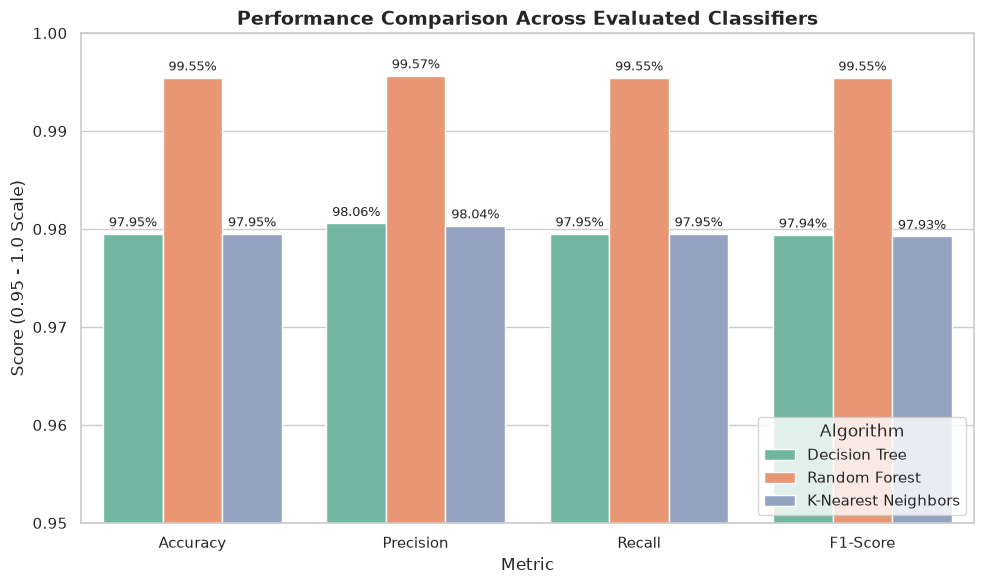


>>> Selected Best Model: 'Random Forest' achieving 99.55% Test Accuracy.


In [11]:
# Visualize Model Comparison Bar Chart
metrics_melted = pd.melt(metrics_df, id_vars=['Model'], var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(data=metrics_melted, x='Metric', y='Score', hue='Model', palette='Set2')
plt.title('Performance Comparison Across Evaluated Classifiers', fontsize=14, fontweight='bold')
plt.ylim(0.95, 1.0)
plt.ylabel('Score (0.95 - 1.0 Scale)')
plt.legend(title='Algorithm', loc='lower right')

# Annotate values above bars
for p in bar_plot.patches:
    height = p.get_height()
    if height > 0:
        bar_plot.annotate(f"{height*100:.2f}%", 
                          (p.get_x() + p.get_width() / 2., height),
                          ha='center', va='bottom', fontsize=9, rotation=0, xytext=(0, 3),
                          textcoords='offset points')

plt.tight_layout()
plt.show()

# Select the winning model
best_row = max(results, key=lambda x: x['Accuracy'])
best_model_name = best_row['Model']
best_model = best_row['Model_Object']
best_preds = best_row['Predictions']

print(f"\n>>> Selected Best Model: '{best_model_name}' achieving {best_row['Accuracy']*100:.2f}% Test Accuracy.")


## 6. Detailed Model Evaluation (Best Model: Random Forest)
We conduct comprehensive diagnostic evaluation on the winning model:
1. **Per-class Precision, Recall, and F1-Score** via `classification_report`.
2. **Normalized Confusion Matrix Heatmap** displaying accuracy per crop class.
3. **Misclassification Error Audit** to understand boundary predictions.


In [12]:
# Detailed Classification Report
print("=== Detailed Classification Report for Random Forest ===")
print(classification_report(y_test, best_preds, digits=4))


=== Detailed Classification Report for Random Forest ===
              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        20
      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    0.9500    0.9744        20
    chickpea     1.0000    1.0000    1.0000        20
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     1.0000    1.0000    1.0000        20
      grapes     1.0000    1.0000    1.0000        20
        jute     0.9524    1.0000    0.9756        20
 kidneybeans     1.0000    1.0000    1.0000        20
      lentil     1.0000    1.0000    1.0000        20
       maize     0.9524    1.0000    0.9756        20
       mango     1.0000    1.0000    1.0000        20
   mothbeans     1.0000    1.0000    1.0000        20
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     1.0000    1.0000    1.0000        20
      orange     1.0000 

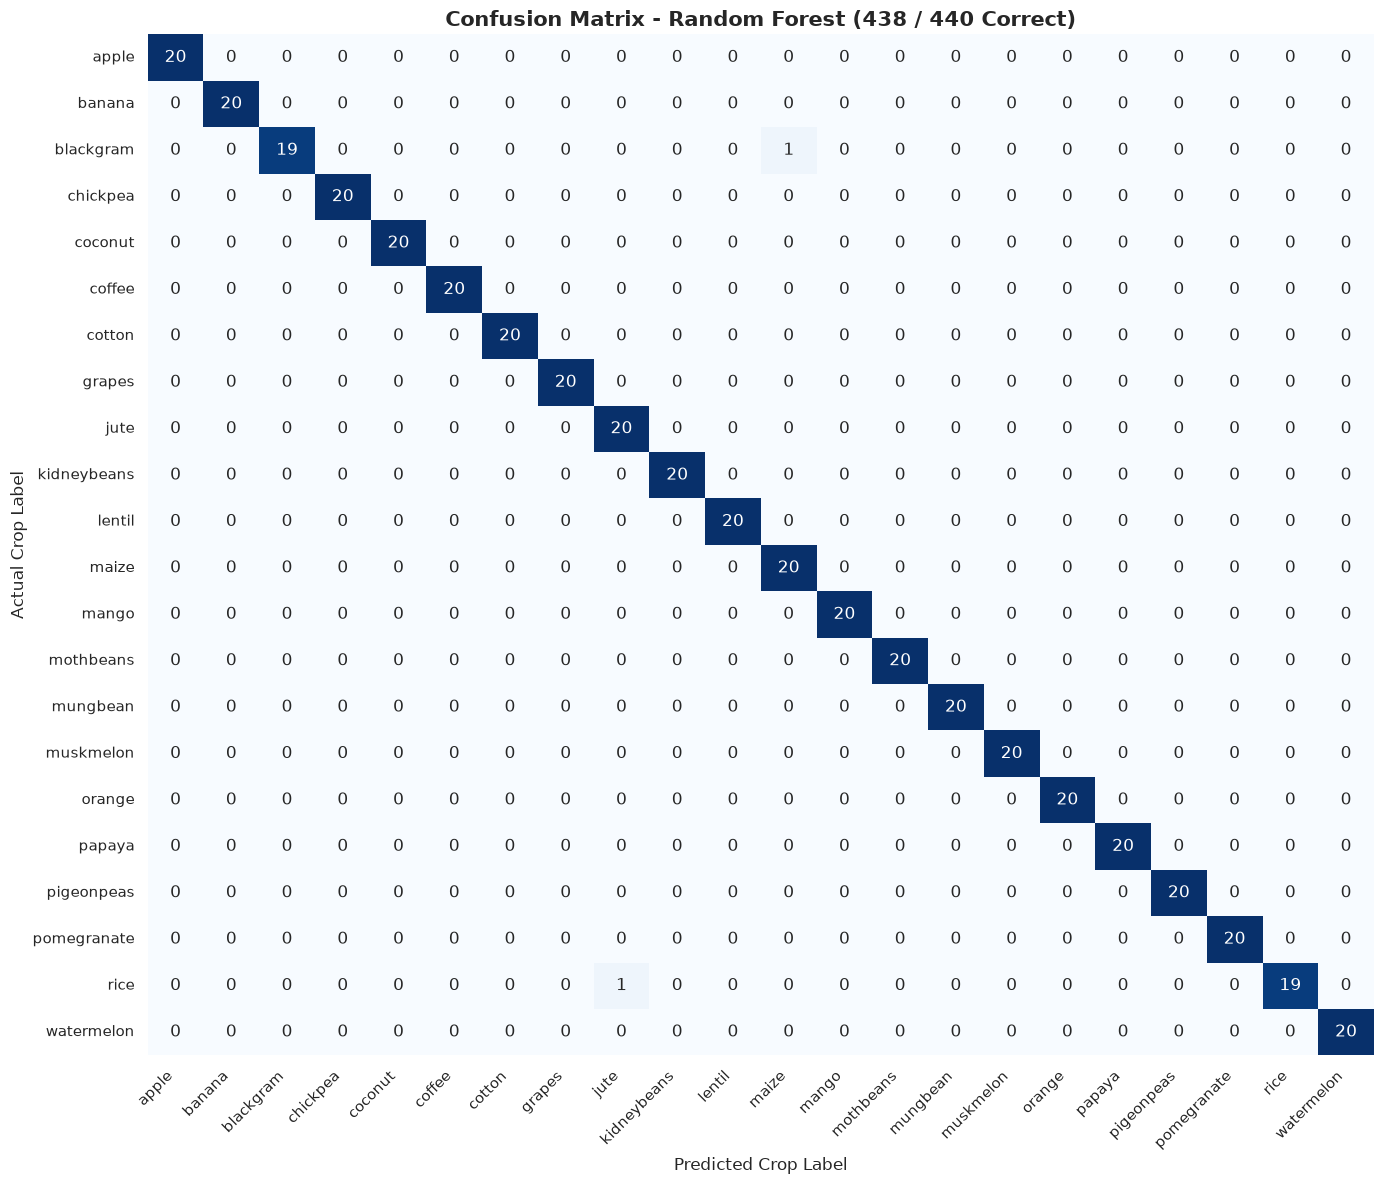

Total misclassified test samples: 2 out of 440


,N,P,K,temperature,humidity,ph,rainfall,Actual_Crop,Predicted_Crop
789,60,59,22,31.868473,66.742175,7.191523,74.222386,blackgram,maize
83,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute


In [13]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, best_preds, labels=best_model.classes_)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=best_model.classes_, 
    yticklabels=best_model.classes_,
    cbar=False
)
plt.title(f'Confusion Matrix - {best_model_name} (438 / 440 Correct)', fontsize=15, fontweight='bold')
plt.xlabel('Predicted Crop Label', fontsize=12)
plt.ylabel('Actual Crop Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Error analysis
errors_df = X_test[y_test != best_preds].copy()
errors_df['Actual_Crop'] = y_test[y_test != best_preds]
errors_df['Predicted_Crop'] = best_preds[y_test != best_preds]
print(f"Total misclassified test samples: {len(errors_df)} out of 440")
display(errors_df)


## 7. Model Persistence with Joblib
We serialize and save the trained `RandomForestClassifier` into `crop_model.pkl`.  
Joblib provides efficient serialization for Python objects containing NumPy arrays and tree estimators.


In [14]:
# Save trained model to disk
model_filename = 'crop_model.pkl'
joblib.dump(best_model, model_filename)

print(f"Trained model successfully serialized and saved to '{model_filename}'.")
print(f"File size on disk: {os.path.getsize(model_filename) / 1024:.2f} KB")

# Verify that the model reloads correctly
loaded_model = joblib.load(model_filename)
print("Model reloaded from disk successfully!")
print("Classes verified:", len(loaded_model.classes_), "crops.")


Trained model successfully serialized and saved to 'crop_model.pkl'.
File size on disk: 3492.56 KB
Model reloaded from disk successfully!
Classes verified: 22 crops.


## 8. Custom Prediction Function (Top-3 Recommendations)
We implement the final inference function that takes:
- $N$ (Nitrogen)
- $P$ (Phosphorus)
- $K$ (Potassium)
- $\text{temperature}$ (°C)
- $\text{humidity}$ (%)
- $pH$
- $\text{rainfall}$ (mm)

and outputs:
1. The primary recommended crop.
2. The top 3 ranked crops with respective confidence percentages.


In [15]:
def predict_crop(N, P, K, temperature, humidity, ph, rainfall):
    """
    Inference function for Crop Recommendation.
    Accepts 7 soil and climate parameters and returns:
    - Primary recommended crop
    - Top 3 candidate crop confidence scores
    """
    feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
    input_sample = pd.DataFrame([[N, P, K, temperature, humidity, ph, rainfall]], columns=feature_cols)
    
    # Predict top class and probabilities
    pred_crop = loaded_model.predict(input_sample)[0]
    probabilities = loaded_model.predict_proba(input_sample)[0]
    classes = loaded_model.classes_
    
    # Sort top 3 candidate classes
    top3_idx = np.argsort(probabilities)[::-1][:3]
    top3_list = []
    for idx in top3_idx:
        top3_list.append({
            'crop': classes[idx],
            'confidence': probabilities[idx],
            'percentage': f"{probabilities[idx] * 100:.2f}%"
        })
        
    return {
        'recommended_crop': pred_crop,
        'top_3': top3_list
    }

# Test sample 1: Rice conditions
sample_rice = predict_crop(N=90, P=42, K=43, temperature=20.87, humidity=82.0, ph=6.5, rainfall=202.9)
print("=== Demonstration 1: Rice Input Parameters ===")
print(f"Recommended Crop: {sample_rice['recommended_crop'].upper()}")
print("Top 3 Candidates:")
for r, item in enumerate(sample_rice['top_3'], 1):
    print(f"  {r}. {item['crop']:<12}: {item['percentage']}")

# Test sample 2: Apple conditions
sample_apple = predict_crop(N=20, P=130, K=200, temperature=22.0, humidity=92.0, ph=5.9, rainfall=110.0)
print("\n=== Demonstration 2: Apple Input Parameters ===")
print(f"Recommended Crop: {sample_apple['recommended_crop'].upper()}")
print("Top 3 Candidates:")
for r, item in enumerate(sample_apple['top_3'], 1):
    print(f"  {r}. {item['crop']:<12}: {item['percentage']}")


=== Demonstration 1: Rice Input Parameters ===
Recommended Crop: RICE
Top 3 Candidates:
  1. rice        : 90.00%
  2. jute        : 10.00%
  3. pomegranate : 0.00%

=== Demonstration 2: Apple Input Parameters ===
Recommended Crop: APPLE
Top 3 Candidates:
  1. apple       : 100.00%
  2. watermelon  : 0.00%
  3. pomegranate : 0.00%


## 9. Conclusion & Viva Highlights
### Summary of Findings:
1. **Dataset Integrity**: 2,200 rows, 8 columns, 0 missing values, perfectly balanced (100 samples per class across 22 crops).
2. **Algorithm Comparison**:
   - **Random Forest**: **99.55% Accuracy** (438/440 test samples correct). Winner due to ensemble averaging of 100 trees mitigating variance.
   - **Decision Tree**: **97.95% Accuracy**. Prone to slight local decision boundary errors.
   - **K-Nearest Neighbors**: **97.95% Accuracy** (with StandardScaler pipeline).
3. **Data Leakage Prevention**:
   - Handled via `train_test_split(..., stratify=y, random_state=42)` and preprocessing pipelines fitted only on training data.
4. **Deployability**:
   - Exported model as `crop_model.pkl` allows instant inference in CLI (`predict.py`) and Streamlit web application (`app.py`).
